# Confidence calibration

How well the model's stated `confidence` matches how often it is right, for one `evaluate` sweep.

After https://arxiv.org/pdf/2512.16030

In [45]:
from analysis.build_data import load_trace_df
from analysis.calibration import (
    category_accuracy_table,
    category_table,
    horizon_plot,
    horizon_table,
    kalshibench_metrics,
    reliability_plot,
)

In [ ]:
# one scoreable forecast per row, from every child run of the sweep (see analysis/build_data.py)
forecasts = load_trace_df("outcome-confidence", run_name="2k-balanced")

## Dataset statistics

In [47]:
category_table(forecasts).round(1)

,N,%,Yes%
category,,,
economics,697,27.8,41.5
elections,582,23.2,27.1
finance,427,17.0,42.9
companies,400,16.0,51.2
politics,400,16.0,25.0


In [48]:
model_table = forecasts.groupby("model").apply(
    kalshibench_metrics, include_groups=False
)
model_table.round(3)

,N,Acc,F1,F1yes,Brier,BSS,ECE,MCE
model,,,,,,,,
claude-fable-5-1,1154.0,67.504,0.592,0.408,0.196,0.158,0.028,0.123
claude-opus-4-5,1144.0,65.559,0.636,0.552,0.219,0.086,0.056,0.400
claude-opus-5-5,1619.0,70.290,0.626,0.456,0.182,0.194,0.021,0.064


## Confidence Analysis

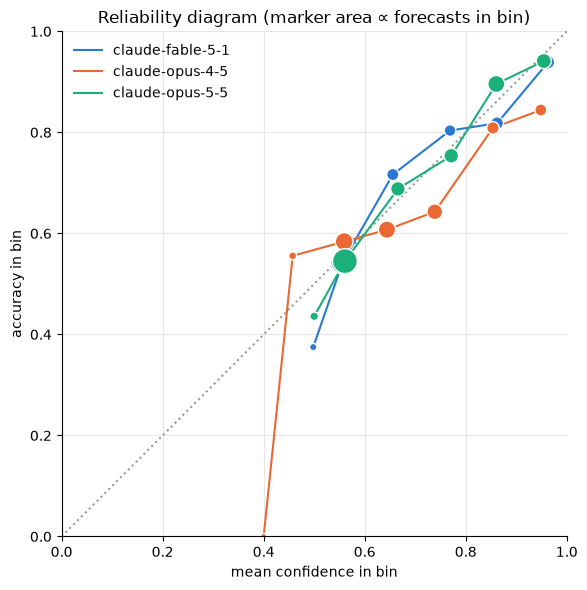

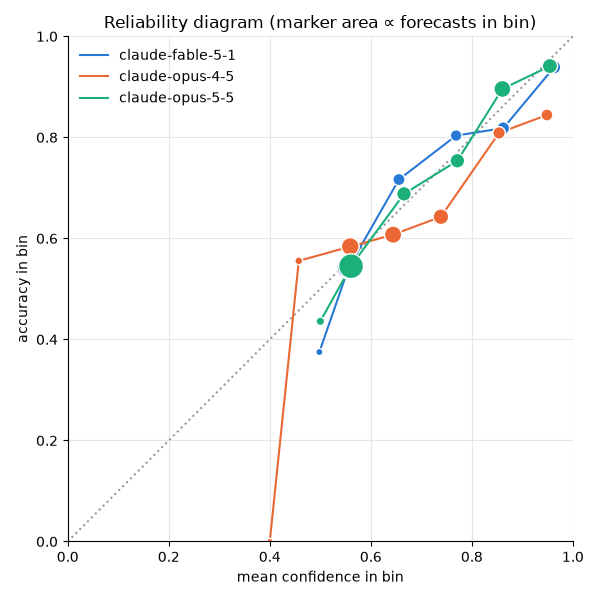

In [49]:
reliability = forecasts.groupby(["model", "confidence_bin"], observed=True).agg(
    n=("correct", "size"), conf=("confidence", "mean"), acc=("correct", "mean")
)
reliability_plot(reliability)

## Market category

Accuracy and confidence by model and market category (see `category_accuracy_table` in `analysis/calibration.py`).

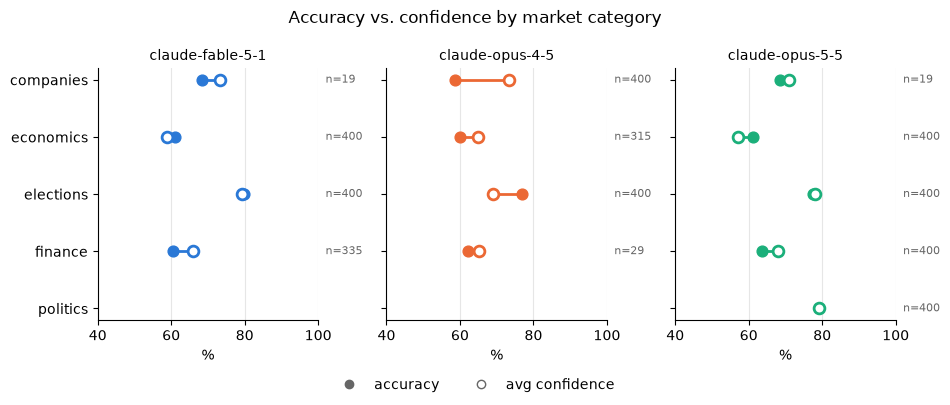

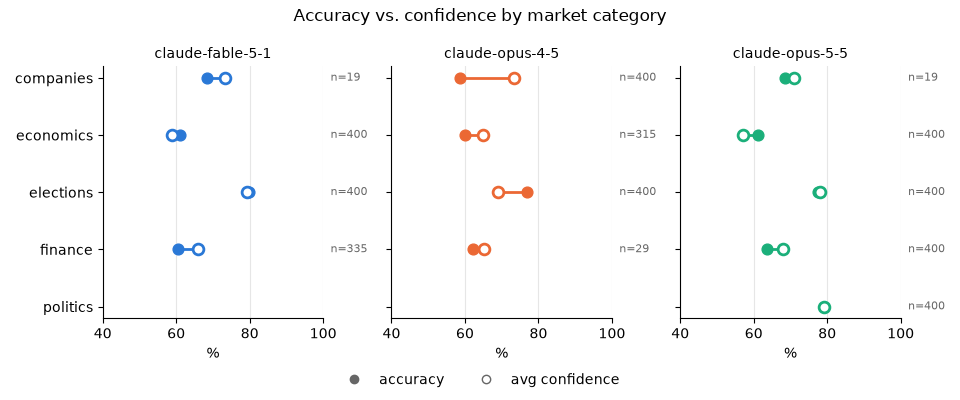

In [50]:
by_category = category_accuracy_table(forecasts)
category_plot(by_category)

## Forecast horizon

Accuracy and confidence by days from the model's training cutoff to the market's close.

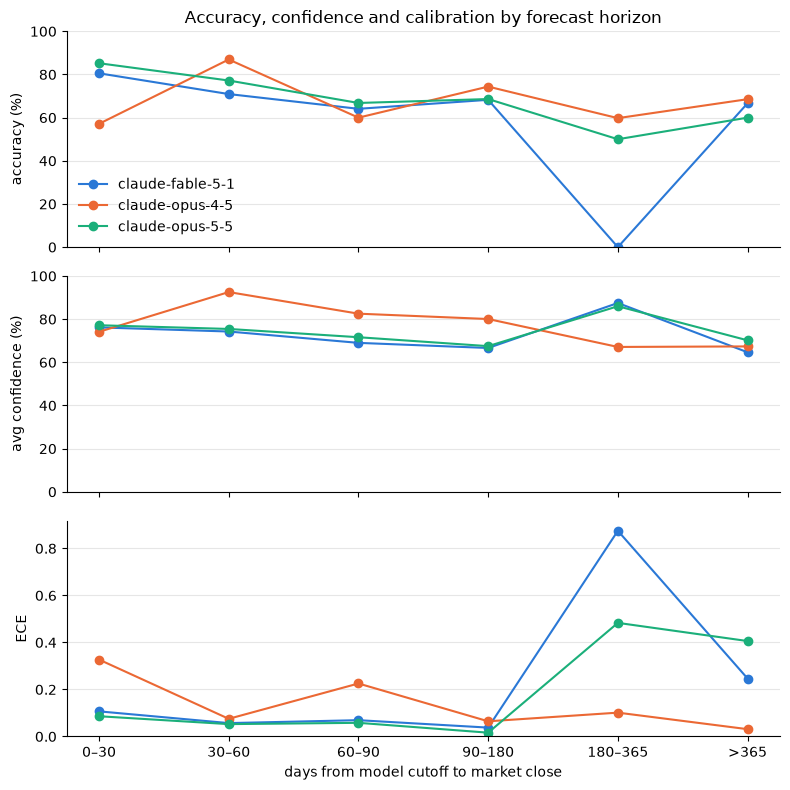

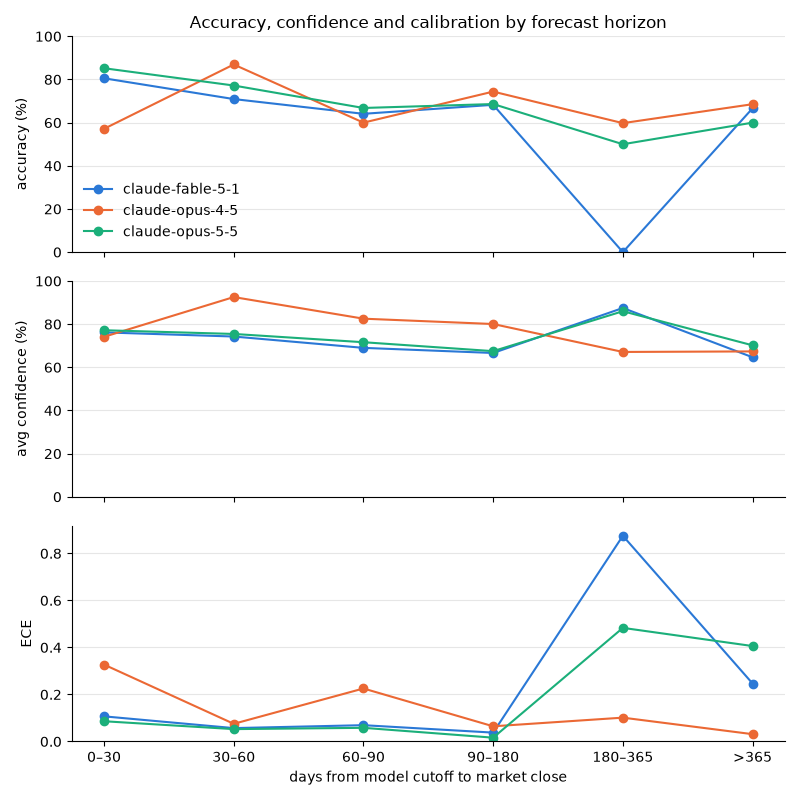

In [51]:
horizon = horizon_table(forecasts)
horizon_plot(horizon)